# Introduction

In part 1 of this assessment, you will complete several requested SQL queries in order to extract data, analyze, and provide insights from a single provided SQL database. You will also visualize the key results of 3 of these queries. There are also several 'Reflection' questions that ask you to write out a text based answer in the provided markdown cell. Following the guided question and answer section, in part 2 you will explore a second dataset on your own using SQL in order to conduct a preliminary analysis. You will be asked to produce a very short slide presentation highlighting the work you did for this second section.

## Objectives
You will be able to:
- Interpret "word problems" and translate them into SQL queries
- Decide and perform whichever type of JOIN is best for retrieving desired data
- Use GROUP BY statements to apply aggregate functions like COUNT, MAX, MIN, and SUM
- Use the HAVING clause to compare different aggregates
- Write subqueries to decompose complex queries
- Visualize data using matplotlib, seaborn, or pandas
- Choose the correct chart type based on the given data


## Part 1: Guided SQL Queries

### Your Task: Querying a Customer Database

![toy car picture](images/toycars.jpg)


### Business Understanding
Your employer sells wholesale miniature models of products such as classic cars, motorcycles, and planes. They want you to pull several reports on different segments of their past customers, in order to better understand past sales as well as determine which customers will receive promotional material. They are also interested in investigating which products have performed the best, as well as having several smaller asks.

In addition to providing the requested data from the SQL database you have also been asked to create some basic visuals to display some of the more insightful information. It is up to your discretion to choose the correct plot/chart type for the data in question. **Questions that want you to visualize the results will be explicitly marked**.

### Data Understanding
You may remember this database from a previous lab. As a refresher, here's the ERD diagram for this database:

![ERD picture](images/ERD.png)

The queries you are asked to write will become more complex over the course of the lab.



### Getting Started
For this assessment you are expected to make use of both sqlite3 and the Pandas libraries in order to write, execute, and return SQL queries as a Pandas DataFrame. Assign each returned answer as its own explicit variable.

For the visualization piece you are expected to utilize either Pandas, Seaborn, or Matplotlib to create your visuals. Make sure you are providing verbose labels and titles according to the data you are being asked to visualize. Do not worry too much about choosing a 'style' or 'context' instead focus on conveying the requested information correctly.

### Step 1: Connect to Data

In the cell below
- Import the necessary libraries
- Establish a connection to the database data.sqlite

In [49]:
# Replace None with your code
# Imports
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt



# Create connection to database
conn= sqlite3.connect("data.sqlite")

### Step 2: Limited Edition California Product
The California sales rep team is interested in running promotional material for a new limited edition model they are releasing based on the famous San Francisco Cable Cars. This product will only be available to customer stores based in California and given its high price value they want to first target promotional material to existing California customers with a high credit limit. Upon communicating with the accounting department, a credit limit of over 25,000 is considered to be high. 

Execute a SQl query that returns which customers the sales rep team wants to market to first.
*Hint*: Make sure creditLimit is numeric.

In [50]:
# Replace NONE with your code
ca_high_credit = pd.read_sql("""
SELECT customerNumber,
       customerName,
       contactFirstName,
       contactLastName,
       phone,
       city,
       state,
       CAST(creditLimit AS REAL) AS creditLimit
  FROM customers
 WHERE state = 'CA'
   AND CAST(creditLimit AS REAL) > 25000
 ORDER BY creditLimit DESC;
""", conn)
ca_high_credit

,customerNumber,customerName,contactFirstName,contactLastName,phone,city,state,creditLimit
0,124,Mini Gifts Distributors Ltd.,Susan,Nelson,4155551450,San Rafael,CA,210500.0
1,239,Collectable Mini Designs Co.,Valarie,Thompson,7605558146,San Diego,CA,105000.0
2,321,Corporate Gift Ideas Co.,Julie,Brown,6505551386,San Francisco,CA,105000.0
3,205,Toys4GrownUps.com,Julie,Young,6265557265,Pasadena,CA,90700.0
4,161,Technics Stores Inc.,Juri,Hashimoto,6505556809,Burlingame,CA,84600.0
5,450,The Sharp Gifts Warehouse,Sue,Frick,4085553659,San Jose,CA,77600.0
6,129,Mini Wheels Co.,Julie,Murphy,6505555787,San Francisco,CA,64600.0
7,487,Signal Collectibles Ltd.,Sue,Taylor,4155554312,Brisbane,CA,60300.0
8,347,"Men 'R' US Retailers, Ltd.",Brian,Chandler,2155554369,Los Angeles,CA,57700.0
9,475,West Coast Collectables Co.,Steve,Thompson,3105553722,Burbank,CA,55400.0


### Step 3: International Collectable Campaign

The international sales rep team has reached out to you to help them identify partners for a 'Collectable' marketing campaign that highlights the potential collectors value in purchasing these model kits. They want to try and promote a 'collect them all' mentality. The team had a great idea to partner with any of their international customers (non-US) who have "Collect" in their name as a tie in to the larger theme.

Execute a SQL that returns the customers in question.

In [51]:
# Replace None with your code
intl_collect = pd.read_sql("""
SELECT customerNumber,
       customerName,
       contactFirstName,
       contactLastName,
       phone,
       city,
       country
  FROM customers
 WHERE customerName LIKE '%Collect%'
   AND country <> 'USA'
 ORDER BY country, customerName;
""", conn)
intl_collect

,customerNumber,customerName,contactFirstName,contactLastName,phone,city,country
0,471,"Australian Collectables, Ltd",Sean,Clenahan,61-9-3844-6555,Glen Waverly,Australia
1,114,"Australian Collectors, Co.",Peter,Ferguson,03 9520 4555,Melbourne,Australia
2,382,Salzburg Collectables,Georg,Pipps,6562-9555,Salzburg,Austria
3,260,"Royal Canadian Collectables, Ltd.",Elizabeth,Lincoln,(604) 555-4555,Tsawassen,Canada
4,227,Heintze Collectables,Palle,Ibsen,86 21 3555,Århus,Denmark
5,353,Reims Collectables,Paul,Henriot,26.47.1555,Reims,France
6,415,"Bavarian Collectables Imports, Co.",Michael,Donnermeyer,+49 89 61 08 9555,Munich,Germany
7,409,Stuttgart Collectable Exchange,Rita,Müller,0711-555361,Stuttgart,Germany
8,211,"King Kong Collectables, Co.",Mike,Gao,+852 2251 1555,Central Hong Kong,Hong Kong
9,189,"Clover Collections, Co.",Dean,Cassidy,+353 1862 1555,Dublin,Ireland


## Reflection Question:

Describe the WHERE clause you used in the above query to a non-technical manager who wants to be ensured that you are properly filtering and only selecting the requested data. How is the operator and conditional expression you are using acting to accomplish this?

## Type your answer in markdown here!

**Answer:** The WHERE clause works like two checkboxes that every customer must tick before they appear on the list.

1. `customerName LIKE '%Collect%'` – this looks for the letters "Collect" anywhere in the store's name. The `%` signs are wildcards meaning "anything can come before or after", so it catches *Collectables*, *Collectors* and *Collections* alike, no matter where the word sits in the name.
2. `country <> 'USA'` – the `<>` operator means "is not equal to", so any customer based in the USA is excluded, leaving only international customers.

The two conditions are joined with `AND`, which means a customer is included **only if both are true**. A US store called "Mini Collectables" is excluded, and a French store without "Collect" in its name is excluded too. The result is 15 international customers, exactly the group the campaign is aimed at.

### Step 4: USA Credit and Inventory Policy - Visual Required
The USA based product team is planning to adjust its credit policies and inventory allocation strategy based on the average credit limit of its customers. They would like to target this strategy at a state level with several goals in mind. 
1. Optimize inventory distribution:
    - States with higher average credit limits might be able to place larger orders, justifying priority in inventory allocation.
    - This could help ensure that states with more purchasing power always have products in stock.
2. Tailor credit policies:
    - Adjust credit limits for new customers based on the state average.
    - Identify states where they might be too conservative or too liberal with credit limits.
3. Target marketing and sales efforts:
    - Focus promotional campaigns on states with higher credit limits, potentially leading to larger orders.
    - Develop strategies to increase sales in states with lower average credit limits.

Execute a SQl query that returns the information required to address this ask.

In [52]:
# Replace None with your code
usa_state_credit = pd.read_sql("""
SELECT state,
       COUNT(*)                                  AS numCustomers,
       ROUND(AVG(CAST(creditLimit AS REAL)), 2)  AS avgCreditLimit
  FROM customers
 WHERE country = 'USA'
 GROUP BY state
 ORDER BY avgCreditLimit DESC;
""", conn)
usa_state_credit

,state,numCustomers,avgCreditLimit
0,NH,1,114200.00
1,NY,6,89966.67
2,PA,3,84766.67
3,CA,11,83854.55
4,NV,1,71800.00
5,MA,9,70755.56
6,CT,4,57350.00
7,NJ,1,43000.00


Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

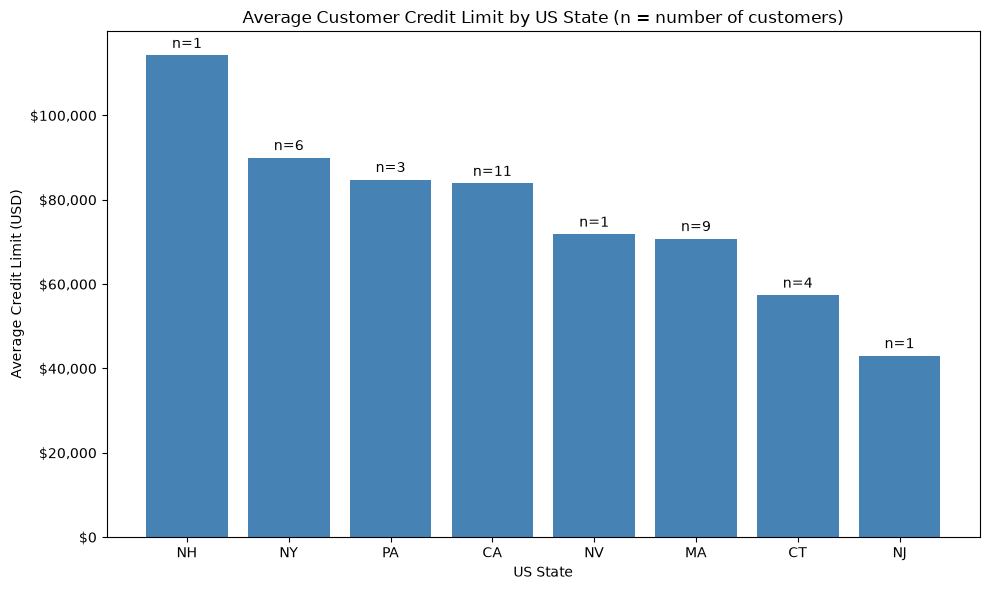

In [53]:
# Replace None with your visual code
# Produce a visual to represent the average credit limit by state
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(usa_state_credit['state'], usa_state_credit['avgCreditLimit'], color='steelblue')
ax.bar_label(bars, labels=[f"n={n}" for n in usa_state_credit['numCustomers']], padding=3)
ax.set_title('Average Customer Credit Limit by US State (n = number of customers)')
ax.set_xlabel('US State')
ax.set_ylabel('Average Credit Limit (USD)')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"${x:,.0f}"))
plt.tight_layout()
plt.show()

### Step 5: Top Customers - Visual Required
The company is approaching its 10 year anniversary and wants to acknowledge and thank its top customers with personalized communication. They have asked you to determine the top 10 customers based on the total amount of payments made, making sure to return the customer name for clarity. 

Execute a SQl query that returns the information required to address this ask.


In [54]:
# Replace None with your code
top_customers = pd.read_sql("""
SELECT c.customerNumber,
       c.customerName,
       ROUND(SUM(CAST(p.amount AS REAL)), 2) AS totalPayments
  FROM customers AS c
  JOIN payments  AS p
    ON c.customerNumber = p.customerNumber
 GROUP BY c.customerNumber, c.customerName
 ORDER BY totalPayments DESC
 LIMIT 10;
""", conn)
top_customers

,customerNumber,customerName,totalPayments
0,141,Euro+ Shopping Channel,715738.98
1,124,Mini Gifts Distributors Ltd.,584188.24
2,114,"Australian Collectors, Co.",180585.07
3,151,Muscle Machine Inc,177913.95
4,148,"Dragon Souveniers, Ltd.",156251.03
5,323,"Down Under Souveniers, Inc",154622.08
6,187,"AV Stores, Co.",148410.09
7,276,"Anna's Decorations, Ltd",137034.22
8,321,Corporate Gift Ideas Co.,132340.78
9,146,"Saveley & Henriot, Co.",130305.35


Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

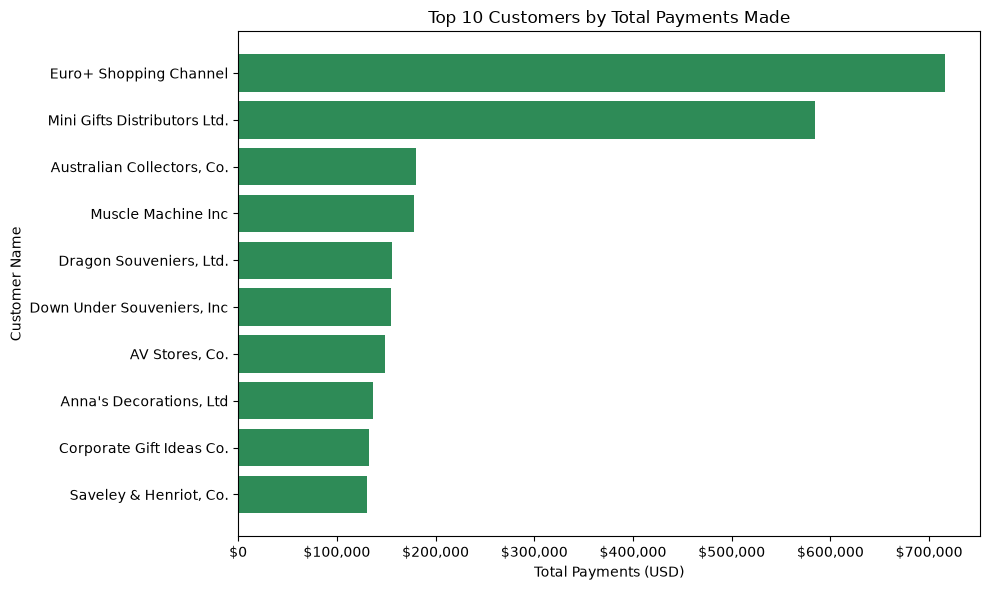

In [55]:
# Replace None with your visual code
# Produce a visual to represent the top ten customers in terms of total payments
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top_customers['customerName'], top_customers['totalPayments'], color='seagreen')
ax.invert_yaxis()
ax.set_title('Top 10 Customers by Total Payments Made')
ax.set_xlabel('Total Payments (USD)')
ax.set_ylabel('Customer Name')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"${x:,.0f}"))
plt.tight_layout()
plt.show()

### Step 6: Top Customer + Product Quantities
The product team is running an analysis on popular and common products sold to each customer in order to try and determine what new products they should be looking at to include in their catalog. This data will also be used by individual sales reps to recommend similar products to each customer next time they place an order. 

They have asked you to query information, for each customer, about any product they have purchased 10 or more units of. In addition they would like the full set of data to be sorted in ascending order by the total amount purchased.

Execute a SQl query that returns the information required to address this ask.

Hint: For this one, you'll need to make use of HAVING, GROUP BY, and ORDER BY — make sure you get the order of them correct!

In [56]:
# Replace None with you code
customer_products = pd.read_sql("""
SELECT c.customerNumber,
       c.customerName,
       p.productCode,
       p.productName,
       SUM(CAST(od.quantityOrdered AS INTEGER)) AS totalQuantity
  FROM customers    AS c
  JOIN orders       AS o  ON c.customerNumber = o.customerNumber
  JOIN orderdetails AS od ON o.orderNumber    = od.orderNumber
  JOIN products     AS p  ON od.productCode   = p.productCode
 GROUP BY c.customerNumber, c.customerName, p.productCode, p.productName
HAVING SUM(CAST(od.quantityOrdered AS INTEGER)) >= 10
 ORDER BY totalQuantity ASC;
""", conn)
customer_products

,customerNumber,customerName,productCode,productName,totalQuantity
0,314,Petit Auto,S18_2949,1913 Ford Model T Speedster,10
1,412,"Extreme Desk Decorations, Ltd",S24_4620,1961 Chevrolet Impala,10
2,119,La Rochelle Gifts,S32_2509,1954 Greyhound Scenicruiser,11
3,328,Tekni Collectables Inc.,S700_1691,American Airlines: B767-300,11
4,450,The Sharp Gifts Warehouse,S24_3191,1969 Chevrolet Camaro Z28,13
...,...,...,...,...,...
2526,141,Euro+ Shopping Channel,S24_3432,2002 Chevy Corvette,174
2527,141,Euro+ Shopping Channel,S12_4473,1957 Chevy Pickup,183
2528,141,Euro+ Shopping Channel,S24_1444,1970 Dodge Coronet,197
2529,141,Euro+ Shopping Channel,S24_2840,1958 Chevy Corvette Limited Edition,245


### Step 7: Product Analysis - Visual Required

The product team is looking into the demand across its different product lines. They are conducting a comprehensive review of its product portfolio and inventory management strategies. You have been asked to query data pertaining to each different product line, that contains the total quantity ordered and the total number of products for each respective product line. By examining the number of products and total quantity ordered for each product line, the company aims to:
1. Optimize product mix:
    - Identify which product lines have the most diverse offerings (high number of products)
    - Determine which lines are most popular (high total quantity ordered)
    - Compare if lines with more products necessarily lead to more orders
2. Improve inventory management:
    - Adjust stock levels based on the popularity of each product line
    - Identify potential overstocking in lines with low order quantities
    - Ensure adequate variety in high-performing product lines
3. Adjust marketing strategy:
    - Focus promotional efforts on product lines with high potential (many products but lower order quantities)
    - Capitalize on the popularity of high-performing lines in marketing campaigns
4. Advise Product development:
    - Invest in expanding product ranges for lines with high order quantities
    - Consider phasing out or revamping product lines with low numbers of products and low order quantities

Hint: Think about how you can and might have to utilize SQL DISTINCT statement

Execute a SQl query that returns the information required to address this ask.

In [57]:
# Replace None with your code
productline_summary = pd.read_sql("""
SELECT p.productLine,
       COUNT(DISTINCT p.productCode)            AS numProducts,
       SUM(CAST(od.quantityOrdered AS INTEGER)) AS totalQuantityOrdered
  FROM products     AS p
  JOIN orderdetails AS od
    ON p.productCode = od.productCode
 GROUP BY p.productLine
 ORDER BY totalQuantityOrdered DESC;
""", conn)
productline_summary

,productLine,numProducts,totalQuantityOrdered
0,Classic Cars,37,35582
1,Vintage Cars,24,22933
2,Motorcycles,13,12778
3,Planes,12,11872
4,Trucks and Buses,11,11001
5,Ships,9,8532
6,Trains,3,2818


Once you have the information returned in a dataframe, select an appropriate visualization to represent the relationship between total quantity ordered and the number of products in order to perform a preliminary investigation into the question of if more products lead to more orders. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

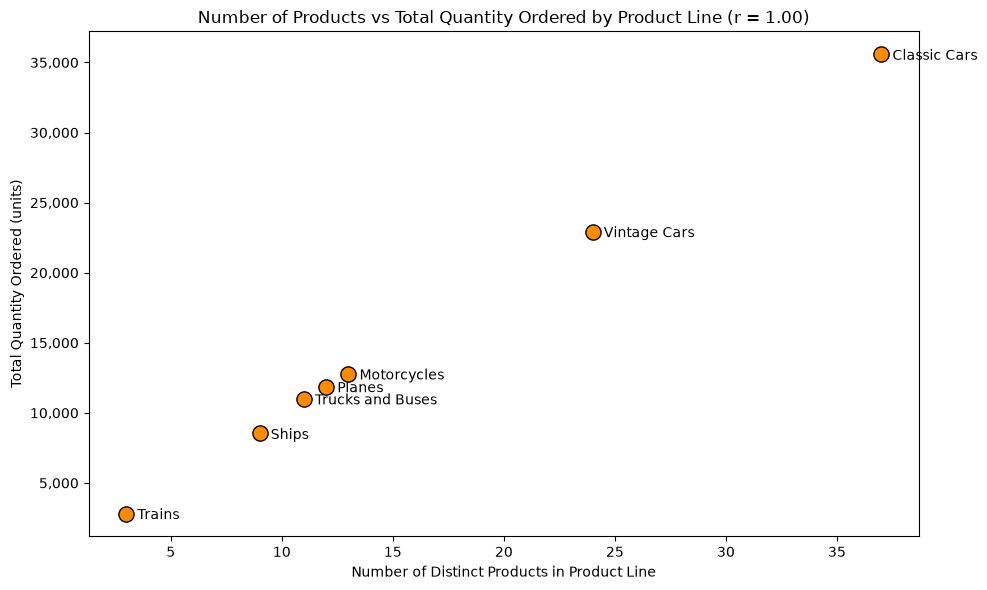

In [58]:
# Replace None with your visual code
# Produce a visual to represent the the relation between number of products and the total amount ordered
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(productline_summary['numProducts'], productline_summary['totalQuantityOrdered'],
           s=120, color='darkorange', edgecolor='black')
for _, row in productline_summary.iterrows():
    ax.annotate(row['productLine'], (row['numProducts'], row['totalQuantityOrdered']),
                textcoords='offset points', xytext=(8, -4))
corr = productline_summary['numProducts'].corr(productline_summary['totalQuantityOrdered'])
ax.set_title(f'Number of Products vs Total Quantity Ordered by Product Line (r = {corr:.2f})')
ax.set_xlabel('Number of Distinct Products in Product Line')
ax.set_ylabel('Total Quantity Ordered (units)')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))
plt.tight_layout()
plt.show()

## Reflection Question:

Please explain your choice in the type of visual you used in order to highlight and represent the data from the above query. In a non-technical manner explain why that chart type makes sense for the information being conveyed. What does this visual convey in the context of the question it was asked for?

## Type your answer in markdown here!

**Answer:** I used a **scatter plot** because the question asks whether two numbers move together: *how many products a line offers* and *how many units customers ordered*. A scatter plot puts one number on each axis and gives every product line a single dot, so you can see straight away whether dots further to the right (more products) also sit higher up (more orders). A bar chart could only show one of these numbers at a time, which would make the relationship harder to see.

The dots form an almost straight rising line (a correlation of r ≈ 1.00, which is almost perfect). Classic Cars has the most products (38) and the most units ordered (about 35,600), and Trains has the fewest of both (3 products, about 2,800 units). Within this data, product lines with more variety do bring in more orders. Two cautions: there are only seven product lines, and this shows the two numbers move together, not that adding products *causes* more orders. Customer demand could just as easily be why the company built out those lines.

### Step 8: Remote Offices
Upper management is considering a shift to hybrid and remote work for certain locations and roles. They have tasked you with providing them data about employees who work in any office that has fewer than 5 total employees so they can better understand how to support those employees remotely when offices are shut down. 

Be sure to include information about the employees job and supervisor so management can adjust everyone to remote work properly.

Hint: Utilize a subquery to find the relevant offices

Execute a SQl query that returns the information required to address this ask.

In [59]:
# Replace None with your code
remote_employees = pd.read_sql("""
SELECT e.employeeNumber,
       e.firstName,
       e.lastName,
       e.jobTitle,
       e.email,
       e.extension,
       o.officeCode,
       o.city      AS officeCity,
       o.country   AS officeCountry,
       m.employeeNumber               AS supervisorNumber,
       m.firstName || ' ' || m.lastName AS supervisorName,
       m.jobTitle                     AS supervisorTitle
  FROM employees      AS e
  JOIN offices        AS o ON e.officeCode = o.officeCode
  LEFT JOIN employees AS m ON e.reportsTo  = m.employeeNumber
 WHERE e.officeCode IN (
        SELECT officeCode
          FROM employees
         GROUP BY officeCode
        HAVING COUNT(*) < 5
       )
 ORDER BY o.officeCode, e.lastName;
""", conn)
remote_employees

,employeeNumber,firstName,lastName,jobTitle,email,extension,officeCode,officeCity,officeCountry,supervisorNumber,supervisorName,supervisorTitle
0,1188,Julie,Firrelli,Sales Rep,jfirrelli@classicmodelcars.com,x2173,2,Boston,USA,1143,Anthony Bow,Sales Manager (NA)
1,1216,Steve,Patterson,Sales Rep,spatterson@classicmodelcars.com,x4334,2,Boston,USA,1143,Anthony Bow,Sales Manager (NA)
2,1286,Foon Yue,Tseng,Sales Rep,ftseng@classicmodelcars.com,x2248,3,NYC,USA,1143,Anthony Bow,Sales Manager (NA)
3,1323,George,Vanauf,Sales Rep,gvanauf@classicmodelcars.com,x4102,3,NYC,USA,1143,Anthony Bow,Sales Manager (NA)
4,1625,Yoshimi,Kato,Sales Rep,ykato@classicmodelcars.com,x102,5,Tokyo,Japan,1621,Mami Nishi,Sales Rep
5,1621,Mami,Nishi,Sales Rep,mnishi@classicmodelcars.com,x101,5,Tokyo,Japan,1056,Mary Patterson,VP Sales
6,1611,Andy,Fixter,Sales Rep,afixter@classicmodelcars.com,x101,6,Sydney,Australia,1088,William Patterson,Sales Manager (APAC)
7,1619,Tom,King,Sales Rep,tking@classicmodelcars.com,x103,6,Sydney,Australia,1088,William Patterson,Sales Manager (APAC)
8,1612,Peter,Marsh,Sales Rep,pmarsh@classicmodelcars.com,x102,6,Sydney,Australia,1088,William Patterson,Sales Manager (APAC)
9,1088,William,Patterson,Sales Manager (APAC),wpatterson@classicmodelcars.com,x4871,6,Sydney,Australia,1056,Mary Patterson,VP Sales


## Reflection Question:

Describe how you decided on the subquery that you used in the query above? This answer can be technically in nature, describing your thought process in how the main query is utilizing the subquery to return the correct data.

## Type your answer in markdown here!

**Answer:** I split the problem into two questions: *which offices are small?* and *who works in those offices?*

The first question is about **groups** (offices), not individual rows, so it needs an aggregate. The subquery groups `employees` by `officeCode` and uses `HAVING COUNT(*) < 5` to keep only offices with fewer than five staff. `HAVING` is required instead of `WHERE` because the filter is on an aggregate value, which only exists after `GROUP BY`. The subquery returns a single column of office codes (2, 3, 5, 6 and 7).

The outer query then answers the second question at the **employee** level. `WHERE e.officeCode IN (subquery)` keeps every employee whose office is in that list. I couldn't do this in a single grouped query, because grouping would collapse employees into one row per office and I need every employee's individual details.

The outer query also adds context: an `INNER JOIN` to `offices` for location, and a **self-join** (`LEFT JOIN employees AS m ON e.reportsTo = m.employeeNumber`) to bring in each supervisor's name and title. It is a `LEFT JOIN` so that an employee with no supervisor would still be listed. The result is 12 employees across 5 offices.

### Step 9: Close the Connection

Now that you are finished executing your queries and retrieving the required information you always want to make sure to close the connection to your database.

In [60]:
# Replace None with your code
conn.close()

### End of Guided Section
In this initial portion of the assessment, you produced several data queries and visualizations for a model company, mainly focused around its customer and product data. You wrote and engineered specific SQL queries to address pertinent questions and asks from the company. Along the way, you utilized many of the major concepts and keywords associated with SQL SELECT queries: FROM, WHERE, GROUP BY, HAVING, ORDER BY, JOIN, SUM, COUNT, and AVG.

## Part 2: Exploratory Analysis with SQL
In this open-ended exploratory section, you will analyze real-world data from the movie industry. As a data analyst, you have the freedom to investigate questions and topics that intrigue you within this dataset. The database schema and Entity-Relationship Diagram (ERD) are provided below for your reference. A general overview and instructions are also provided below.

In [61]:
# Run this cell without changes
import zipfile

zip_file_path = 'im.db.zip'
extract_to_path = './'

with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall(extract_to_path)

# Connection
conn4 = sqlite3.connect('im.db')

# Schema
schema_df = pd.read_sql("""
SElECT * FROM sqlite_master                        
""", conn4)
schema_df

,type,name,tbl_name,rootpage,sql
0,table,movie_basics,movie_basics,2,"CREATE TABLE ""movie_basics"" (\n""movie_id"" TEXT..."
1,table,directors,directors,3,"CREATE TABLE ""directors"" (\n""movie_id"" TEXT,\n..."
2,table,known_for,known_for,4,"CREATE TABLE ""known_for"" (\n""person_id"" TEXT,\..."
3,table,movie_akas,movie_akas,5,"CREATE TABLE ""movie_akas"" (\n""movie_id"" TEXT,\..."
4,table,movie_ratings,movie_ratings,6,"CREATE TABLE ""movie_ratings"" (\n""movie_id"" TEX..."
5,table,persons,persons,7,"CREATE TABLE ""persons"" (\n""person_id"" TEXT,\n ..."
6,table,principals,principals,8,"CREATE TABLE ""principals"" (\n""movie_id"" TEXT,\..."
7,table,writers,writers,9,"CREATE TABLE ""writers"" (\n""movie_id"" TEXT,\n ..."


## The Data

![movie ERD](images/movie_data_erd.jpeg)
### Database Content:

- Source: IMDB
- Time Range: Movies released between 2010 and 2019
- Note: Exclude any movies with a start_year after 2019 as this data is not current or accurate

Available Data Categories:
- Genre
- Runtime
- Personnel (writers, directors, actors)
- Movie ratings

### Objectives:

Initial Exploration:
- Use SQL in combination with Pandas to explore the database
- Identify interesting trends, patterns, or relationships in the data

Business Question Formulation:
- Develop at least one substantial business question for deeper analysis
- Ensure the question is relevant, specific, and can be addressed with the available data

Data Cleaning Assessment:
- Identify potential data cleaning tasks necessary for your deeper analysis
- Note: You are not required to perform the cleaning, only to recognize and list the necessary tasks

Null Value Handling:
- Be aware that the dataset contains null values in certain fields
- Exclude these null values from your exploration
- Do not attempt to input or fill in missing information

### Deliverables:

You need to produce a short slide presentation (3-5 slides) that highlights the three key deliverables below. Utilize a data visualization to support the second deliverable.

1. A summary of your initial data exploration findings
    - Can be bulleted or sentence form
2. At least one well-formulated business question for further analysis
    - Should stem from a relevant trend or pattern your initial exploration identified
3. A list of potential data cleaning tasks identified during your exploration
    - This can and should include things like data normalization/standardization and null handling

Tips for Success:

Begin with broad exploratory queries to understand the data's scope and content. Then focus on honing in on interesting relationships between different data categories. Consider industry trends, audience preferences, or financial aspects when formulating your business question. Pay attention to data quality issues, inconsistencies, or limitations that might affect your analysis. Remember, the goal is to demonstrate your analytical thinking and ability to derive meaningful insights from complex datasets. Good luck with your exploration!

NOTE: You do not need to explore every aspect of this database. Find something that you think is interesting or relevant about the data and focus your exploration there.

In [62]:
# Begin your code here
# Begin your code here
# 1. Size of each table, to understand the scope of the data
tables = ['movie_basics', 'movie_ratings', 'movie_akas', 'directors', 'writers',
          'principals', 'persons', 'known_for']
table_sizes = pd.concat(
    [pd.read_sql(f"SELECT '{t}' AS table_name, COUNT(*) AS num_rows FROM {t};", conn4) for t in tables],
    ignore_index=True)
table_sizes

,table_name,num_rows
0,movie_basics,146144
1,movie_ratings,73856
2,movie_akas,331703
3,directors,291174
4,writers,255873
5,principals,1028186
6,persons,606648
7,known_for,1638260


In [63]:
# 2. Movies per start_year - checks the 2010-2019 range and spots out-of-range years
movies_per_year = pd.read_sql("""
SELECT start_year,
       COUNT(*) AS num_movies
  FROM movie_basics
 GROUP BY start_year
 ORDER BY start_year;
""", conn4)
movies_per_year

,start_year,num_movies
0,2010,11849
1,2011,12900
2,2012,13787
3,2013,14709
4,2014,15589
5,2015,16243
6,2016,17272
7,2017,17504
8,2018,16849
9,2019,8379


In [64]:
# 3. Null counts in the key movie columns (start_year <= 2019 only)
null_check = pd.read_sql("""
SELECT COUNT(*)                                          AS total_movies,
       SUM(CASE WHEN runtime_minutes IS NULL THEN 1 ELSE 0 END) AS null_runtime,
       SUM(CASE WHEN genres          IS NULL THEN 1 ELSE 0 END) AS null_genres,
       SUM(CASE WHEN r.movie_id      IS NULL THEN 1 ELSE 0 END) AS no_rating
  FROM movie_basics AS b
  LEFT JOIN movie_ratings AS r ON b.movie_id = r.movie_id
 WHERE b.start_year <= 2019;
""", conn4)
null_check

,total_movies,null_runtime,null_genres,no_rating
0,145081,30765,5359,71225


In [65]:
# 4. How reliable are the ratings? Many movies have very few votes
vote_summary = pd.read_sql("""
SELECT COUNT(*)                                           AS rated_movies,
       SUM(CASE WHEN numvotes < 100   THEN 1 ELSE 0 END)  AS under_100_votes,
       SUM(CASE WHEN numvotes >= 1000 THEN 1 ELSE 0 END)  AS at_least_1000_votes,
       ROUND(AVG(averagerating), 2)                       AS avg_rating,
       MAX(numvotes)                                      AS max_votes
  FROM movie_ratings AS r
  JOIN movie_basics  AS b ON r.movie_id = b.movie_id
 WHERE b.start_year <= 2019;
""", conn4)
vote_summary

,rated_movies,under_100_votes,at_least_1000_votes,avg_rating,max_votes
0,73856,45103,9617,6.33,1841066


In [66]:
# 5. Runtime outliers - impossible values that would need cleaning
runtime_outliers = pd.read_sql("""
SELECT primary_title, start_year, runtime_minutes
  FROM movie_basics
 WHERE runtime_minutes IS NOT NULL
   AND (runtime_minutes > 300 OR runtime_minutes < 40)
 ORDER BY runtime_minutes DESC
 LIMIT 10;
""", conn4)
runtime_outliers

,primary_title,start_year,runtime_minutes
0,Logistics,2012,51420.0
1,Modern Times Forever,2011,14400.0
2,Nari,2017,6017.0
3,Hunger!,2015,6000.0
4,London EC1,2015,5460.0
5,Ember Glow,2015,4980.0
6,Deregulation,2012,4200.0
7,Nieuwe Tieten,2013,4080.0
8,City of Eternal Spring,2010,3450.0
9,A 2nd generation film,2013,3077.0


In [67]:
# 6. Genre performance. genres is a comma-separated list (e.g. "Action,Crime,Drama"),
# so a recursive CTE splits it into one row per movie per genre.
# Filters: released 2010-2019, genres not null, at least 1,000 votes (reliable ratings).
genre_performance = pd.read_sql("""
WITH RECURSIVE split(movie_id, genre, rest) AS (
    SELECT movie_id, '', genres || ','
      FROM movie_basics
     WHERE genres IS NOT NULL
       AND start_year <= 2019
    UNION ALL
    SELECT movie_id,
           SUBSTR(rest, 1, INSTR(rest, ',') - 1),
           SUBSTR(rest, INSTR(rest, ',') + 1)
      FROM split
     WHERE rest <> ''
)
SELECT s.genre,
       COUNT(*)                                                  AS num_movies,
       ROUND(AVG(r.averagerating), 2)                            AS avg_rating,
       ROUND(AVG(r.numvotes))                                    AS avg_votes,
       SUM(CASE WHEN r.numvotes >= 100000 THEN 1 ELSE 0 END)     AS hits_100k_votes,
       ROUND(100.0 * SUM(CASE WHEN r.numvotes >= 100000 THEN 1 ELSE 0 END) / COUNT(*), 1) AS hit_rate_pct
  FROM split AS s
  JOIN movie_ratings AS r ON s.movie_id = r.movie_id
 WHERE s.genre <> ''
   AND r.numvotes >= 1000
 GROUP BY s.genre
HAVING COUNT(*) >= 150
 ORDER BY avg_votes DESC;
""", conn4)
genre_performance

,genre,num_movies,avg_rating,avg_votes,hits_100k_votes,hit_rate_pct
0,Adventure,1002,6.16,83667.0,219,21.9
1,Sci-Fi,533,5.71,80107.0,99,18.6
2,Fantasy,464,6.00,56227.0,76,16.4
3,Action,1998,6.01,50215.0,276,13.8
4,Animation,376,6.68,40310.0,41,10.9
5,Mystery,711,6.06,34183.0,57,8.0
6,Biography,701,6.96,30359.0,51,7.3
7,Crime,1318,6.27,29662.0,101,7.7
8,Family,283,6.33,29202.0,23,8.1
9,Thriller,1797,5.90,26191.0,115,6.4


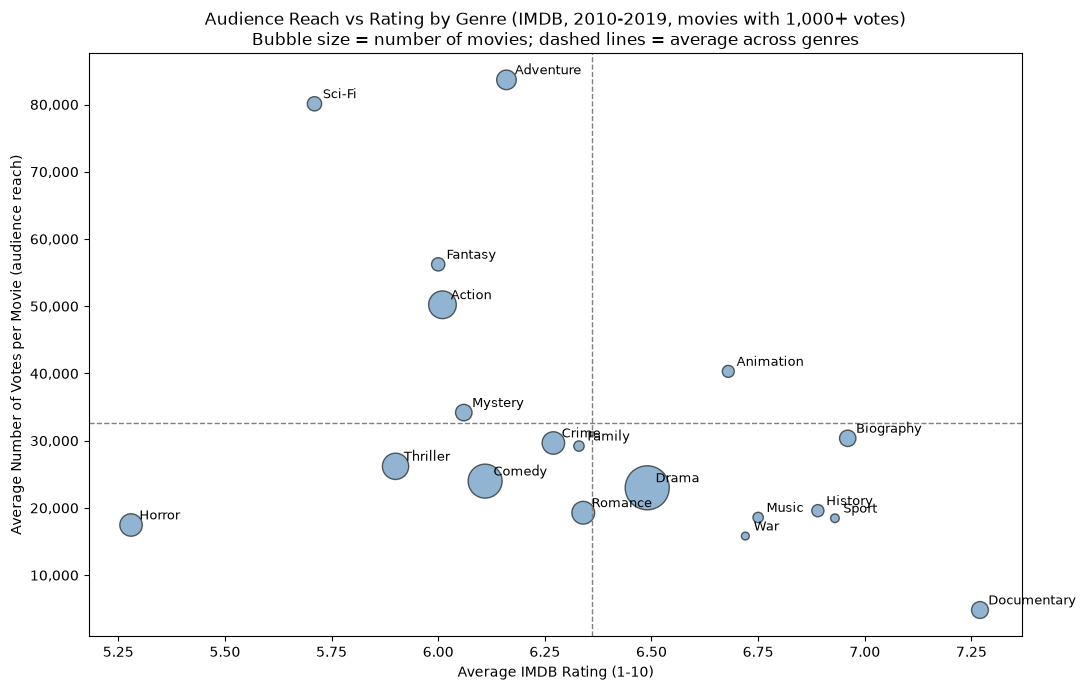

In [68]:
# 7. Visual: audience reach (avg votes) vs audience approval (avg rating) by genre
fig, ax = plt.subplots(figsize=(11, 7))
ax.scatter(genre_performance['avg_rating'], genre_performance['avg_votes'],
           s=genre_performance['num_movies'] / 5, alpha=0.6, color='steelblue', edgecolor='black')
for _, row in genre_performance.iterrows():
    ax.annotate(row['genre'], (row['avg_rating'], row['avg_votes']),
                textcoords='offset points', xytext=(6, 4), fontsize=9)
ax.axvline(genre_performance['avg_rating'].mean(), color='grey', linestyle='--', linewidth=1)
ax.axhline(genre_performance['avg_votes'].mean(), color='grey', linestyle='--', linewidth=1)
ax.set_title('Audience Reach vs Rating by Genre (IMDB, 2010-2019, movies with 1,000+ votes)\n'
             'Bubble size = number of movies; dashed lines = average across genres')
ax.set_xlabel('Average IMDB Rating (1-10)')
ax.set_ylabel('Average Number of Votes per Movie (audience reach)')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))
plt.tight_layout()
plt.show()

In [69]:
# 8. Does runtime relate to rating and reach? (excludes outlier runtimes)
runtime_performance = pd.read_sql("""
SELECT CASE
         WHEN b.runtime_minutes < 80  THEN '1. Under 80 min'
         WHEN b.runtime_minutes < 100 THEN '2. 80-99 min'
         WHEN b.runtime_minutes < 120 THEN '3. 100-119 min'
         WHEN b.runtime_minutes < 140 THEN '4. 120-139 min'
         ELSE '5. 140+ min'
       END                              AS runtime_band,
       COUNT(*)                         AS num_movies,
       ROUND(AVG(r.averagerating), 2)   AS avg_rating,
       ROUND(AVG(r.numvotes))           AS avg_votes
  FROM movie_basics  AS b
  JOIN movie_ratings AS r ON b.movie_id = r.movie_id
 WHERE b.start_year <= 2019
   AND b.runtime_minutes BETWEEN 40 AND 240
   AND r.numvotes >= 1000
 GROUP BY runtime_band
 ORDER BY runtime_band;
""", conn4)
runtime_performance

,runtime_band,num_movies,avg_rating,avg_votes
0,1. Under 80 min,293,6.20,3424.0
1,2. 80-99 min,4188,5.85,13141.0
2,3. 100-119 min,3129,6.44,31964.0
3,4. 120-139 min,1280,6.78,47958.0
4,5. 140+ min,713,6.85,49030.0


In [70]:
# 9. Data quality: duplicate titles and duplicate person names
duplicate_titles = pd.read_sql("""
SELECT primary_title, COUNT(*) AS num_movies
  FROM movie_basics
 GROUP BY primary_title
HAVING COUNT(*) > 1
 ORDER BY num_movies DESC
 LIMIT 5;
""", conn4)
duplicate_directors = pd.read_sql("""
SELECT COUNT(*) AS director_rows,
       (SELECT COUNT(*) FROM (SELECT DISTINCT movie_id, person_id FROM directors)) AS distinct_pairs
  FROM directors;
""", conn4)
display(duplicate_titles, duplicate_directors)

,primary_title,num_movies
0,Home,24
1,The Return,20
2,Broken,20
3,Homecoming,16
4,Alone,16


,director_rows,distinct_pairs
0,291174,163535


In [71]:
# Close the IMDB connection
conn4.close()